# **Notebook 1: Data Understanding & Exploratory Data Analysis**
## Assignment: Hybrid RAG & Fine-Tuning for Customer Support
---

### TO-DO: Before Running This Notebook

**Files you NEED for this notebook:**
- [ ] `corporate_policies/` folder with `.md` SOP files uploaded to Colab:
  - `refund_policy.md`, `shipping_delays.md`, `password_reset.md`, `technical_troubleshooting.md`, `escalation_matrix.md`
- [ ] Internet access (to download Bitext dataset from HuggingFace)

**Files this notebook will CREATE:**
- [ ] `sampled_data.csv` — Cleaned, deduplicated, 4000-row sample of the Bitext dataset
  _(Required by: Notebook 2 — Data Preparation)_

> **Note:** Tasks 1.1 (Define Project Scope) and 1.4 (Design Methodology) are documented in your **Project Proposal PDF**, not this notebook. This notebook covers Tasks **1.2** and **1.3**.

---

## **Stage 1: Data Understanding & EDA**
### **Task 1.2: Understand and Assess Data**

#### **1.2.1 Inspect Dataset Structure [2 marks]**
**The Task:** Identify the presence of the corporate policy files within the local environment and successfully download the `bitext` customer support dataset from Hugging Face. Print the dataset information.

**Hints & Tips:**
* Use `glob` to find `.md` files in your workspace, and `load_dataset` for the bitext data.
* The dataset ID is `bitext/Bitext-customer-support-llm-chatbot-training-dataset` — it contains ~26,872 rows.
* Key columns: `instruction` (user query), `intent` (target class), `category` (broader group).

**Why we are doing it:** To ensure the local environment is properly configured with our knowledge base before reading data.
**How we are doing it:** Check the `corporate_policies` directory, load the dataset, and use `.info()`.

**Learner Inference:** If the files load correctly, your environment is stable. Seeing the 'intent' column confirms the target variable you will train your model to extract in Stage 4.

In [16]:
# YOUR CODE HERE
import glob
import pandas as pd
from datasets import load_dataset

# 1. Verify corporate policy .md files
policy_files = sorted(glob.glob("/content/corporate_policies/*.md"))
print(f"Found {len(policy_files)} policy files:")
for f in policy_files:
    print(" -", f)

# 2. Load Bitext dataset from Hugging Face
ds = load_dataset("bitext/Bitext-customer-support-llm-chatbot-training-dataset", split="train")
df = ds.to_pandas()

# 3. Print dataset info
print("\nDataset Info:")
df.info()

Found 5 policy files:
 - /content/corporate_policies/escalation_matrix.md
 - /content/corporate_policies/password_reset.md
 - /content/corporate_policies/refund_policy.md
 - /content/corporate_policies/shipping_delays.md
 - /content/corporate_policies/technical_troubleshooting.md

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26872 entries, 0 to 26871
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   flags        26872 non-null  object
 1   instruction  26872 non-null  object
 2   category     26872 non-null  object
 3   intent       26872 non-null  object
 4   response     26872 non-null  object
dtypes: object(5)
memory usage: 1.0+ MB


#### **1.2.2 Quantify Dataset Characteristics [3 marks]**
**The Task:** Calculate the original size of the dataset, identify the number of unique intents, and randomly sample the dataset down to 4,000 rows.

**Hints & Tips:**
* Use `len()`, `.nunique()`, and `.sample(4000, random_state=42)`.
* `random_state=42` ensures reproducibility — everyone gets the same sample.
* With 4000 rows and 27 intents, you'll get ~148 examples per intent on average.

**Parameter Tuning:**
* `sample(n)` — try 1000–5000 per the workflow spec:
  - `1000`: Fast (~1 min), lower accuracy
  - `4000`: Moderate (~3 min), better accuracy (recommended)
  - `5000`: Slower, best accuracy, may hit T4 memory limits

**Learner Inference:** Capping at 4000 rows keeps your Stage 4 training loop to minutes while providing enough examples per intent.

In [3]:
# YOUR CODE HERE
# 1. Original size of the dataset
original_size = len(df)

# 2. Number of unique intents
num_unique_intents = df["intent"].nunique()

# 3. Randomly sample down to 4,000 rows with a fixed seed for reproducibility
df_sampled = df.sample(n=4000, random_state=42)

print(f"Original dataset size: {original_size}")
print(f"Number of unique intents: {num_unique_intents}")
print(f"Sampled dataset size: {len(df_sampled)}")

Original dataset size: 26872
Number of unique intents: 27
Sampled dataset size: 4000


#### **1.2.3 Validate Sample Quality [2 marks]**
**The Task:** Identify and remove records containing null values or duplicated customer instructions using normalised deduplication.

**Hints & Tips:**
* Use `.isnull().sum()` to check nulls.
* Simple `drop_duplicates` misses near-dupes like `"Where is my order?"` vs `"where is my order?"`.
* Normalise to lowercase + strip whitespace BEFORE deduplicating to catch these.
* The Bitext dataset typically has ~15 near-duplicates in a 4000-row sample.

**Learner Inference:** Cleaning now prevents "garbage-in, garbage-out". Duplicate prompts can cause leakage between train and test sets later.

In [14]:
# YOUR CODE HERE
# 1. Check for null values in the sampled dataset
print("Null values before cleaning:")
print(df_sampled.isnull().sum())

# Drop rows with any null values if present
df_sampled = df_sampled.dropna().copy()

# 2. Normalised deduplication on customer instructions ('instruction' column)
before_dedup = len(df_sampled)

# Create a temporary normalised column (lowercase + stripped whitespace)
df_sampled["norm_instruction"] = (
    df_sampled["instruction"].astype(str).str.lower().str.strip()
)

# Remove near-duplicates based on normalised instruction
df_sampled = df_sampled.drop_duplicates(subset=["norm_instruction"]).copy()

# Remove the temporary helper column
df_sampled = df_sampled.drop(columns=["norm_instruction"])

after_dedup = len(df_sampled)
print(f"\nRows before deduplication: {before_dedup}")
print(f"Duplicates removed: {before_dedup - after_dedup}")
print(f"Cleaned sample size: {after_dedup}")

Null values before cleaning:
flags          0
instruction    0
category       0
intent         0
response       0
dtype: int64

Rows before deduplication: 4000
Duplicates removed: 98
Cleaned sample size: 3902


### **Task 1.3: Perform Exploratory Data Analysis**

#### **1.3.1 Perform Univariate Analysis [2 marks]**
**The Task:** Plot the top 10 most frequent customer intents using a horizontal bar chart.

**Hints & Tips:**
* Use a Seaborn `countplot` with `order=df['intent'].value_counts().index[:10]`.
* Check if any single intent dominates >80% of data — signals severe class imbalance.
* `palette="viridis"` works well for accessibility.

**Learner Inference:** This visual reveals class imbalance. If one intent dominates, your fine-tuned router becomes biased toward guessing it.

/tmp/ipykernel_905/1353637976.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


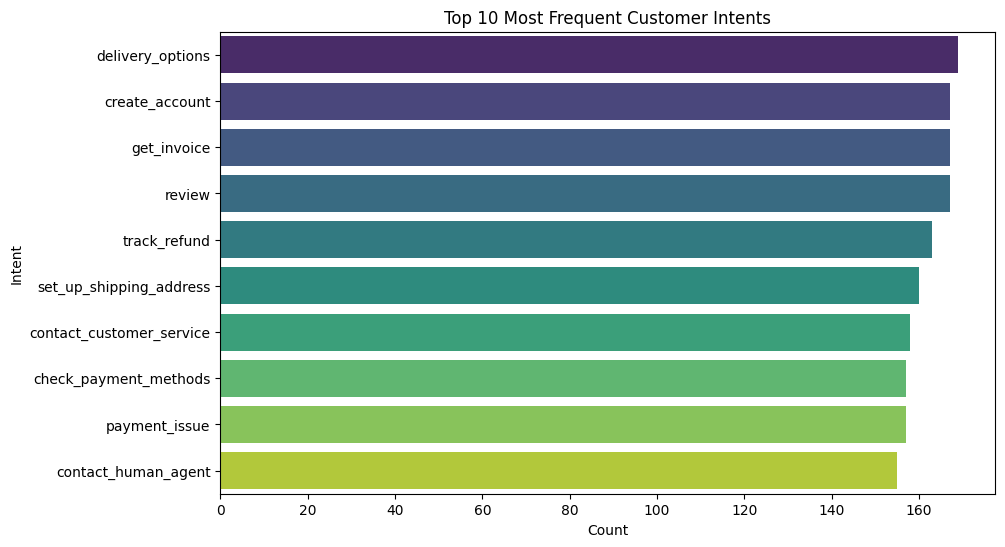

Top intent accounts for 4.23% of the cleaned sample.


In [9]:
# YOUR CODE HERE
import matplotlib.pyplot as plt
import seaborn as sns

# Get the top 10 most frequent intents
top_10_intents = df_sampled["intent"].value_counts().index[:10]

# Plot horizontal bar chart
plt.figure(figsize=(10, 6))
sns.countplot(
    data=df_sampled[df_sampled["intent"].isin(top_10_intents)],
    y="intent",
    order=top_10_intents,
    palette="viridis",
)

plt.title("Top 10 Most Frequent Customer Intents")
plt.xlabel("Count")
plt.ylabel("Intent")
plt.show()

# Optional: Check share of the top intent
top_share = (df_sampled["intent"].value_counts().iloc[0] / len(df_sampled)) * 100
print(f"Top intent accounts for {top_share:.2f}% of the cleaned sample.")

#### **1.3.2 Perform Bivariate Analysis [2 marks]**
**The Task:** Read the text from the uploaded Markdown SOP files and fit a `TfidfVectorizer` (with `stop_words='english'`) to transform them into vectors.

**Hints & Tips:**
* Read files into a list of strings first using `open(f, 'r').read()`.
* `TfidfVectorizer(stop_words="english")` removes common words, keeping meaningful terms.
* The resulting matrix shape should be `(num_docs, num_unique_terms)`.

**Learner Inference:** This transforms raw text into math, letting you prove whether your policies are distinct enough for an AI to tell apart.

In [10]:
# YOUR CODE HERE
import glob
from sklearn.feature_extraction.text import TfidfVectorizer

# 1. Get all SOP Markdown files
sop_files = sorted(glob.glob("/content/corporate_policies/*.md"))
sop_names = [f.split("/")[-1] for f in sop_files]

# 2. Read file contents into a list of strings
sop_texts = [open(f, "r", encoding="utf-8").read() for f in sop_files]

# 3. Fit and transform using TfidfVectorizer
vectorizer = TfidfVectorizer(stop_words="english")
tfidf_matrix = vectorizer.fit_transform(sop_texts)

print(f"Number of SOP documents loaded: {len(sop_texts)}")
print(f"TF-IDF matrix shape (docs, unique_terms): {tfidf_matrix.shape}")

Number of SOP documents loaded: 5
TF-IDF matrix shape (docs, unique_terms): (5, 445)


In [11]:
import pandas as pd

pd.DataFrame(
    tfidf_matrix.toarray(),
    index=sop_names,
    columns=vectorizer.get_feature_names_out(),
).iloc[:, :10]

,10,12,21,24,30,48,60,access,accidental,account
escalation_matrix.md,0.000000,0.00000,0.00000,0.000000,0.00000,0.00000,0.000000,0.000000,0.00000,0.105180
password_reset.md,0.048347,0.00000,0.00000,0.000000,0.00000,0.00000,0.059924,0.048347,0.00000,0.120396
refund_policy.md,0.000000,0.06437,0.00000,0.000000,0.06437,0.00000,0.000000,0.000000,0.06437,0.000000
shipping_delays.md,0.063801,0.00000,0.07908,0.158161,0.00000,0.07908,0.000000,0.000000,0.00000,0.000000
technical_troubleshooting.md,0.000000,0.00000,0.00000,0.000000,0.00000,0.00000,0.000000,0.059365,0.00000,0.197112


#### **1.3.3 Generate Visualisations [2 marks]**
**The Task:** Calculate cosine similarity between the TF-IDF vectors of the SOP documents and plot an annotated heatmap.

**Hints & Tips:**
* Use `cosine_similarity` from sklearn and `sns.heatmap` with `annot=True`.
* Diagonal should always be 1.0 (document vs itself).
* Off-diagonal >0.5 = high overlap (RAG may struggle); <0.3 = low overlap (good retrieval).

**Learner Inference:** High overlap (dark off-diagonal squares) means the RAG system struggles to fetch the right doc. Low overlap proves retrieval will be accurate.

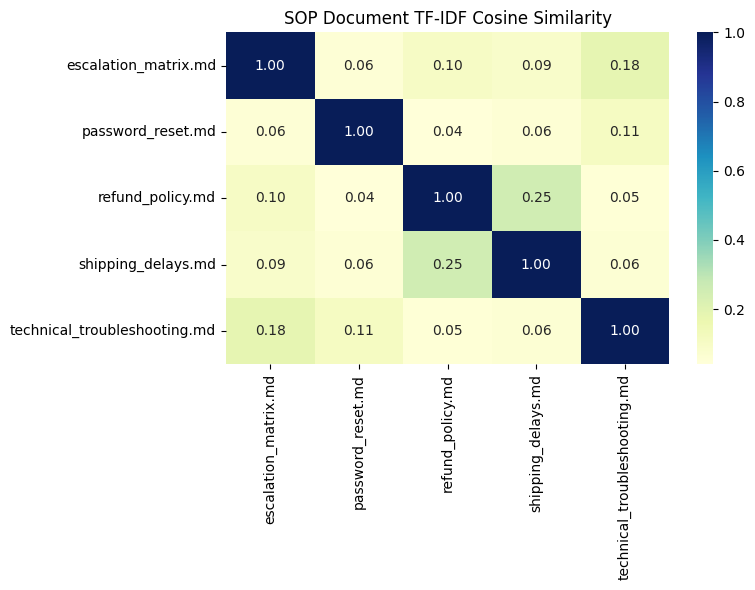

In [12]:
# YOUR CODE HERE
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics.pairwise import cosine_similarity

# 1. Calculate pairwise cosine similarity across SOP TF-IDF vectors
sim_matrix = cosine_similarity(tfidf_matrix)

# 2. Plot annotated heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(
    sim_matrix,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    xticklabels=sop_names,
    yticklabels=sop_names,
)
plt.title("SOP Document TF-IDF Cosine Similarity")
plt.tight_layout()
plt.show()

---
## Save Artifacts for Notebook 2

**IMPORTANT:** This cell saves the cleaned DataFrame. Notebook 2 depends on this file.

In [15]:
# YOUR CODE HERE
# Save cleaned DataFrame for Notebook 2
output_path = "sampled_data.csv"
df_sampled.to_csv(output_path, index=False)
print(f"Saved {len(df_sampled)} cleaned rows to {output_path}")

Saved 3902 cleaned rows to sampled_data.csv


---
## END-OF-NOTEBOOK CHECKLIST

> **IMPORTANT: Verify all items before proceeding to Notebook 2.**

- [ ] Bitext dataset loaded and `.info()` printed
- [ ] Dataset sampled to 4000 rows (or chosen size 1000–5000)
- [ ] Nulls inspected, near-duplicates removed via normalised dedup
- [ ] Top 10 intent bar chart rendered
- [ ] TF-IDF vectorisation completed on SOP documents
- [ ] Cosine similarity heatmap rendered
- [ ] **`sampled_data.csv` saved to disk** ← _CRITICAL for Notebook 2_
- [ ] `corporate_policies/` folder still accessible ← _Needed in Notebooks 2 and 4_

**If any item is unchecked, fix it before moving on.**